# Sequential versus joint discrimination

Companion comparison for paper §6: sequential Heuristic (VND + Beam) and joint Greedy on matched inputs and budgets. Select execution settings below; algorithms retain separate checkpoints.


In [9]:
from pathlib import Path
import sys
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

working = Path.cwd().resolve()
PROJECT = working / 'problem-2-3-comparison' if (working / 'problem-2-3-comparison').is_dir() else working
if not (PROJECT / 'comparison').is_dir():
    raise RuntimeError('Start Jupyter in the repository root or problem-2-3-comparison.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from comparison.config import Config
from comparison.dataset import prepare_dataset
from comparison.runner import run_comparison, cache_coverage
from comparison.reporting import make_report

RUN_MODE = 'full'  # 'full' or 'compact' (the previous test dataset).
RUN_ANALYSIS = False  # False requires all selected checkpoints; never starts a search.
SEQUENTIAL_ALGORITHM = 'vnd_beam'  # 'vnd_beam' or 'greedy'
JOINT_ALGORITHM = 'greedy'  # 'greedy' or 'vnd'
CONFIG = Config(
    mode=RUN_MODE,
    sequential_algorithm=SEQUENTIAL_ALGORITHM,
    joint_algorithm=JOINT_ALGORITHM,
    seed=20261018,
    beam_width=3,
    sequential_max_iterations=30,  # Original Problem 2 default; None removes the cap.
    bootstrap_samples=2000,
    bootstrap_seed=20261019,
)
print(f'Mode: {RUN_MODE}; planned instances: {6 * len(CONFIG.sizes)**2 * CONFIG.replicates}')


Mode: full; planned instances: 7290


## Common inputs and budgets

Load/generate the shared dataset. Budgets are rounded fractions of $\min(N_{\mathrm{LB}}^{\mathrm{joint}}-1,50)$; zero budgets are omitted and duplicates evaluated once.


In [10]:
DATASET, MANIFEST = prepare_dataset(PROJECT, CONFIG)
print(cache_coverage(PROJECT, CONFIG, MANIFEST))
excluded = [c for c in MANIFEST['cases'] if c['status'] == 'excluded']
print(f"Inputs: {DATASET}; eligible: {len(MANIFEST['cases']) - len(excluded)}; excluded: {len(excluded)}")


{'sequential': {'algorithm': 'vnd_beam', 'available': 55249, 'missing': 0, 'total': 55249}, 'joint': {'algorithm': 'greedy', 'available': 55249, 'missing': 0, 'total': 55249}}
Inputs: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-3-comparison/data/full/d35aec82f2cde0d5; eligible: 7290; excluded: 0


In [11]:
# Each completed method/budget is checkpointed; rerunning resumes automatically.
ROWS, OUTPUT = run_comparison(PROJECT, CONFIG, DATASET, MANIFEST, run=RUN_ANALYSIS)
print(f'Matched instance/budget records: {len(ROWS)}; output: {OUTPUT}')


Instances evaluated/loaded: 1/7290
Instances evaluated/loaded: 2/7290
Instances evaluated/loaded: 3/7290
Instances evaluated/loaded: 4/7290
Instances evaluated/loaded: 5/7290
Instances evaluated/loaded: 6/7290
Instances evaluated/loaded: 7/7290
Instances evaluated/loaded: 8/7290
Instances evaluated/loaded: 9/7290
Instances evaluated/loaded: 10/7290
Instances evaluated/loaded: 11/7290
Instances evaluated/loaded: 12/7290
Instances evaluated/loaded: 13/7290
Instances evaluated/loaded: 14/7290
Instances evaluated/loaded: 15/7290
Instances evaluated/loaded: 16/7290
Instances evaluated/loaded: 17/7290
Instances evaluated/loaded: 18/7290
Instances evaluated/loaded: 19/7290
Instances evaluated/loaded: 20/7290
Instances evaluated/loaded: 21/7290
Instances evaluated/loaded: 22/7290
Instances evaluated/loaded: 23/7290
Instances evaluated/loaded: 24/7290
Instances evaluated/loaded: 25/7290
Instances evaluated/loaded: 26/7290
Instances evaluated/loaded: 27/7290
Instances evaluated/loaded: 28/7290
I

## Error figure and family table

The figure averages matched target-fraction groups with pointwise 95% instance-bootstrap intervals. The family table averages unique budgets per instance, then weights instances equally.


**Figure 1 — Sequential vs. Joint Error**

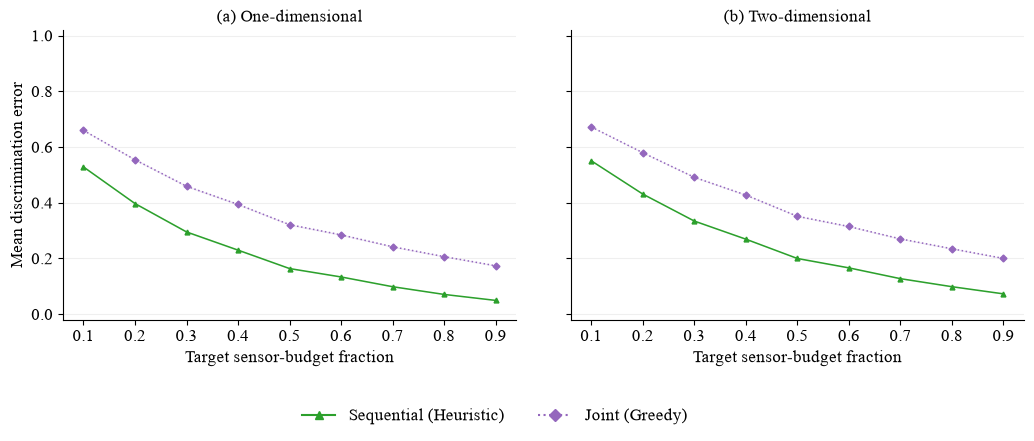

**Table 1 — Field-Family Comparison**

| Dimension | Field Family | Sequential Mean Error | Joint Mean Error |
|---|---|---:|---:|
| 1D | Gaussian | 0.213830 | 0.360465 |
| 1D | Sinusoidal | 0.208325 | 0.330292 |
| 1D | Quadratic | 0.202658 | 0.370514 |
| 2D | Gaussian | 0.253115 | 0.383471 |
| 2D | Sinusoidal | 0.252594 | 0.369602 |
| 2D | Quadratic | 0.207412 | 0.383765 |

In [12]:
import importlib
import comparison.reporting as _reporting
_reporting = importlib.reload(_reporting)
figure, table_markdown = _reporting.make_report(ROWS, OUTPUT, CONFIG)
display(Markdown('**Figure 1 — Sequential vs. Joint Error**'))
display(figure)
plt.close(figure)
display(Markdown('**Table 1 — Field-Family Comparison**'))
display(Markdown(table_markdown))


In [13]:
# Compare each unique instance/budget once; lower error wins.
import math

TIE_TOLERANCE = 1e-9
matched = {}
for row in ROWS:
    key = (row['dimension'], row['instance_id'], row['N'])
    if key in matched:
        raise ValueError(f'Duplicate instance/budget: {key}')
    difference = row['sequential_error'] - row['joint_error']
    if not math.isfinite(difference):
        raise ValueError(f'Nonfinite error difference: {key}')
    matched[key] = difference

lines = ['| Dimension | Comparisons | Sequential better | Joint better | Ties |',
         '|---|---:|---:|---:|---:|']
for label, dimension in [('Overall', None), ('1D', 1), ('2D', 2)]:
    differences = [difference for key, difference in matched.items()
                   if dimension is None or key[0] == dimension]
    count = len(differences)
    sequential_wins = sum(d < -TIE_TOLERANCE for d in differences)
    joint_wins = sum(d > TIE_TOLERANCE for d in differences)
    ties = count - sequential_wins - joint_wins
    percentages = [f'{100 * n / count:.2f}%' if count else '—'
                   for n in (sequential_wins, joint_wins, ties)]
    lines.append(f'| {label} | {count:,} | ' + ' | '.join(percentages) + ' |')

display(Markdown('**Sequential vs. Joint: percentage of comparisons won**'))
display(Markdown('\n'.join(lines)))
display(Markdown('Each matched instance and unique sensor count has equal weight. '
                 f'Absolute error differences of at most {TIE_TOLERANCE:g} count as ties.'))


**Sequential vs. Joint: percentage of comparisons won**

| Dimension | Comparisons | Sequential better | Joint better | Ties |
|---|---:|---:|---:|---:|
| Overall | 55,249 | 98.46% | 0.22% | 1.32% |
| 1D | 28,069 | 98.57% | 0.16% | 1.28% |
| 2D | 27,180 | 98.35% | 0.28% | 1.36% |

Each matched instance and unique sensor count has equal weight. Absolute error differences of at most 1e-09 count as ties.

## Mean sensor usage

Separate 1D/2D means over unique instance–budget pairs. Sequential uses $C_{\mathrm{seq}}=\mathbb{E}[\sum_{r=1}^{K-1}\min\{n_{m_r},N_{i_rj_rm_r}\}]$ from saved trees; joint uses N in one round. No searches are run by this cell.


In [14]:
import importlib
import comparison.usage_summary as _usage_summary
_usage_summary = importlib.reload(_usage_summary)
usage = _usage_summary.mean_sensor_uses(ROWS, OUTPUT, DATASET, MANIFEST, CONFIG)

columns = list(usage['table'][0])
lines = ['| ' + ' | '.join(columns) + ' |', '|---|---|---:|---:|---:|']
for row in usage['table']:
    values = [f'{value:.3f}' if isinstance(value, float) else str(value)
              for value in row.values()]
    lines.append('| ' + ' | '.join(values) + ' |')
display(Markdown('\n'.join(lines)))
display(Markdown(
    'Means across unique evaluated instance–budget pairs: '
    + ', '.join(f"{dimension}D: {count:,}" for dimension, count in usage['evaluations_by_dimension'].items())
    + '. Joint sensing rounds = 1; sequential sensing rounds = K − 1.'
))


Saved sensor-use summary: 5,000/55,249 evaluations
Saved sensor-use summary: 10,000/55,249 evaluations
Saved sensor-use summary: 15,000/55,249 evaluations
Saved sensor-use summary: 20,000/55,249 evaluations
Saved sensor-use summary: 25,000/55,249 evaluations
Saved sensor-use summary: 30,000/55,249 evaluations
Saved sensor-use summary: 35,000/55,249 evaluations
Saved sensor-use summary: 40,000/55,249 evaluations
Saved sensor-use summary: 45,000/55,249 evaluations
Saved sensor-use summary: 50,000/55,249 evaluations
Saved sensor-use summary: 55,000/55,249 evaluations


| Dataset | Method | Mean allocated sensors (N) | Mean sensing rounds | Mean expected total sensor uses |
|---|---|---:|---:|---:|
| 1D | Sequential (Heuristic) | 12.457 | 5.398 | 31.675 |
| 1D | Joint (Greedy) | 12.457 | 1 | 12.457 |
| 2D | Sequential (Heuristic) | 13.734 | 5.339 | 35.094 |
| 2D | Joint (Greedy) | 13.734 | 1 | 13.734 |

Means across unique evaluated instance–budget pairs: 1D: 28,069, 2D: 27,180. Joint sensing rounds = 1; sequential sensing rounds = K − 1.